In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [68]:
df = pd.read_csv('PaySimDataset.csv')

In [69]:
df.head(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [70]:
df.shape

(6362620, 11)

This Dataset contains 11 Columns and 6362620 Rows.

In [71]:
df.tail()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6362615,743,CASH_OUT,339682.13,C786484425,339682.13,0.0,C776919290,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,C1529008245,6311409.28,0.0,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,C1162922333,6311409.28,0.0,C1365125890,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,C1685995037,850002.52,0.0,C2080388513,0.00,0.00,1,0
6362619,743,CASH_OUT,850002.52,C1280323807,850002.52,0.0,C873221189,6510099.11,7360101.63,1,0


In [72]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

These are the Columns that will be used.

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [74]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [75]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

There is no Null Data in this Dataset.

In [76]:
df.duplicated().sum()

np.int64(0)

There are no Duplicate values in this Dataset.

In [77]:
df['type'].unique()

array(['PAYMENT', 'TRANSFER', 'CASH_OUT', 'DEBIT', 'CASH_IN'],
      dtype=object)

Unique values in Transaction Types columns

In [78]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [79]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud vs Non-Fraud distribution

In [80]:
df['isFraud'].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

In this dataset:
0 = Not Fraud,
1 = Fraud

Means 99.88%(approx.) data is not fraud, 0.13%(approx) data is fraud.
This confirms that the dataset is highly imbalanced.

In [81]:
pd.crosstab(df['type'], df['isFraud'])

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


Transaction type vs fraud

In [82]:
#Fraud rate for each transaction type

df.groupby('type')['isFraud'].mean()

type
CASH_IN     0.000000
CASH_OUT    0.001840
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.007688
Name: isFraud, dtype: float64

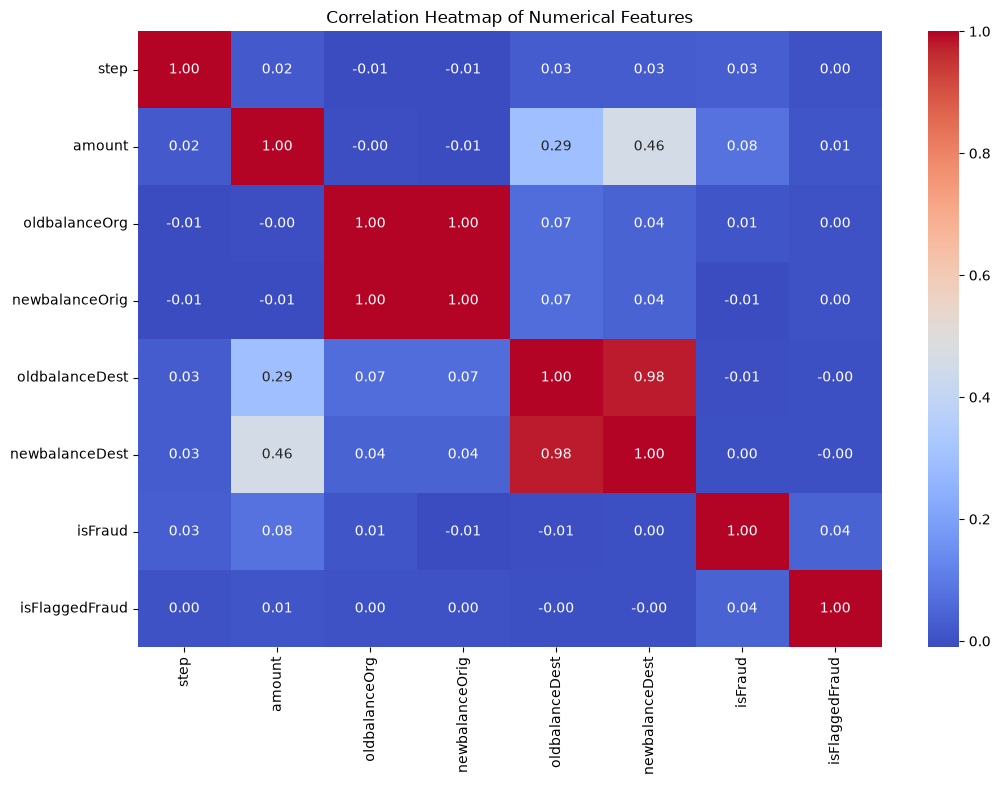

In [83]:
#correlation between numerical features, Heatmap

import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

+1 → Strong positive correlation, 
-1 → Strong negative correlation, 
0 → Little or no correlation

In [84]:
# correlations with isFraud

corr_matrix['isFraud'].sort_values(ascending=False)

isFraud           1.000000
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
oldbalanceOrg     0.010154
newbalanceDest    0.000535
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
Name: isFraud, dtype: float64

In [85]:
# statistical differences between Fraud and Non-Fraud

df.groupby('isFraud').mean(numeric_only=True)

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFlaggedFraud
isFraud,,,,,,,
0,243.235663,1.781970e+05,8.328287e+05,855970.228109,1.101421e+06,1.224926e+06,0.000000
1,368.413856,1.467967e+06,1.649668e+06,192392.631836,5.442496e+05,1.279708e+06,0.001948


This helps compare things such as:
1) Transaction amount
2) Account balances
3) Destination balances
4) Fraud patterns

EXPLORATORY DATA ANALYSIS (EDA)

In [86]:
import seaborn as sns
import matplotlib.pyplot as plt

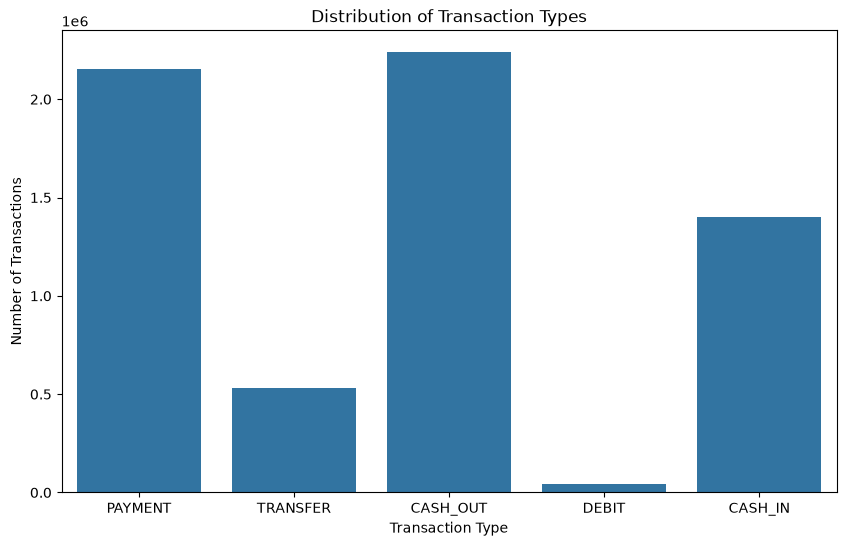

In [87]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='type')
plt.title('Distribution of Transaction Types')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')

plt.show()

From the above graph we can analyse that Cash_Out trasanction type occurs most frequently followed by Payment. The least transaction type is Debit.

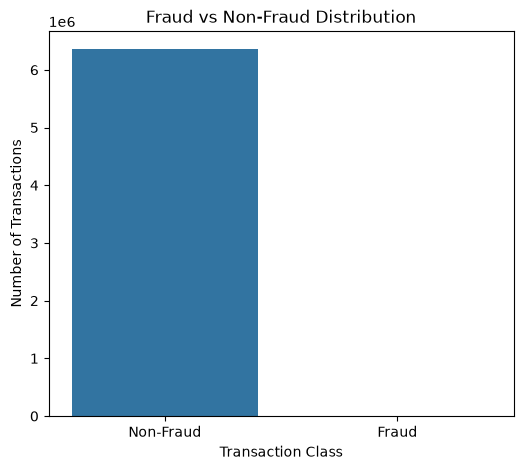

In [88]:
plt.figure(figsize=(6, 5))
sns.countplot(data=df, x='isFraud')
plt.title('Fraud vs Non-Fraud Distribution')
plt.xlabel('Transaction Class')
plt.ylabel('Number of Transactions')
plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

The fraud bar looks extremely small because there are only around 0.13% fraudulent transactions.

In [89]:
fraud_by_type = pd.crosstab(df['type'], df['isFraud'])
print(fraud_by_type)

isFraud         0     1
type                   
CASH_IN   1399284     0
CASH_OUT  2233384  4116
DEBIT       41432     0
PAYMENT   2151495     0
TRANSFER   528812  4097


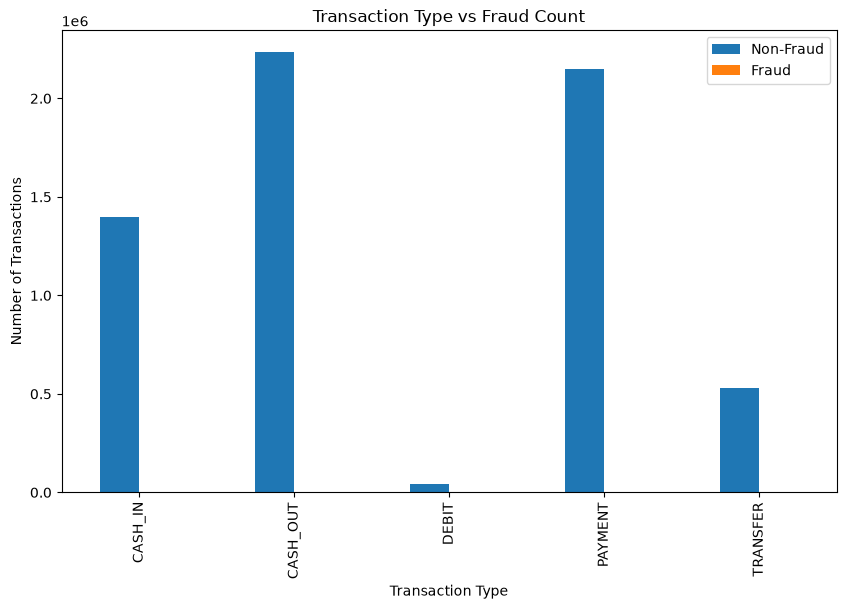

In [90]:
fraud_by_type.plot(
    kind='bar',
    figsize=(10, 6)
)
plt.title('Transaction Type vs Fraud Count')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.legend(['Non-Fraud', 'Fraud'])

plt.show()

it can be observed that fraudulent transactions are concentrated mainly in cash_out and transfer transaction types.

In [91]:
fraud_rate_by_type = (
    df.groupby('type')['isFraud']
    .mean() * 100
)
print(fraud_rate_by_type)

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64


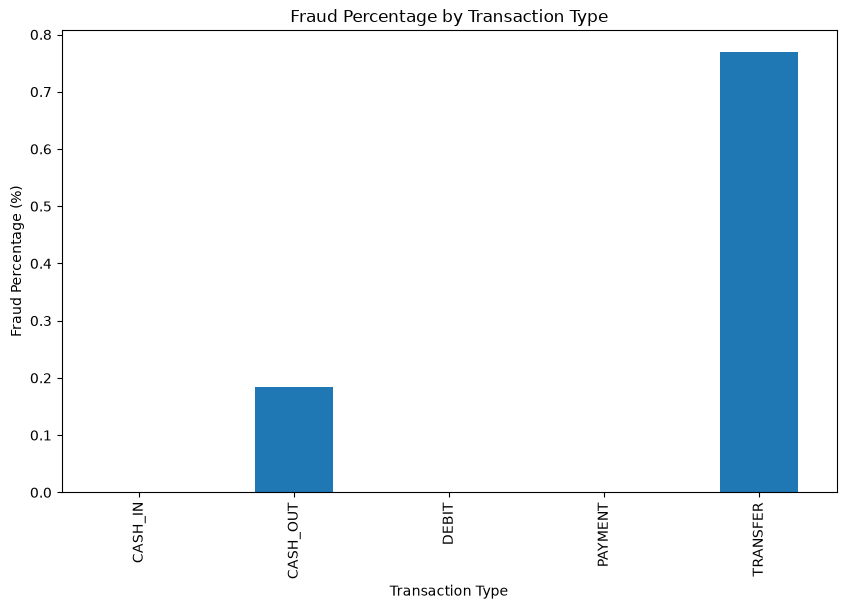

In [92]:
plt.figure(figsize=(10, 6))
fraud_rate_by_type.plot(
    kind='bar'
)
plt.title('Fraud Percentage by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Fraud Percentage (%)')

plt.show()

In [93]:
sample_df = df.sample(
    n=100000,
    random_state=42
)

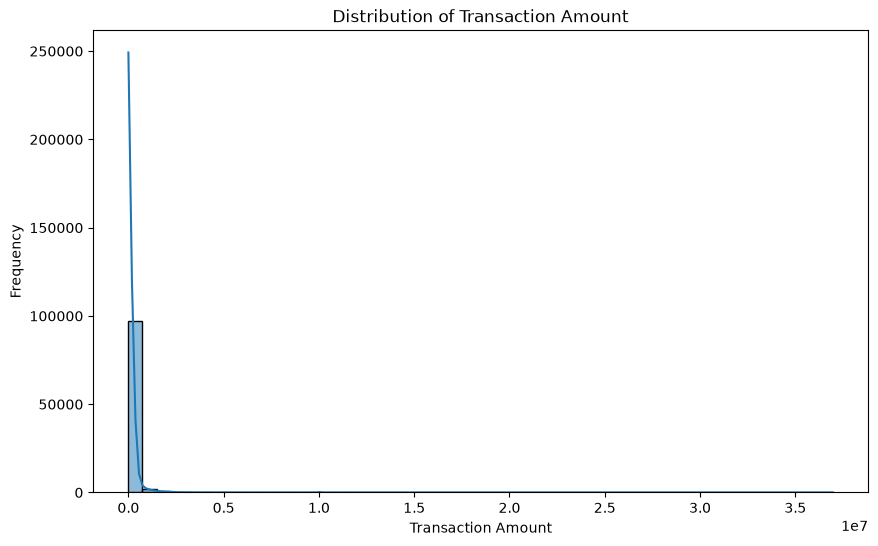

In [94]:
plt.figure(figsize=(10, 6))
sns.histplot(
    sample_df['amount'],
    bins=50,
    kde=True
)
plt.title('Distribution of Transaction Amount')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

Because transaction amounts can be extremely large, the graph may be heavily skewed.

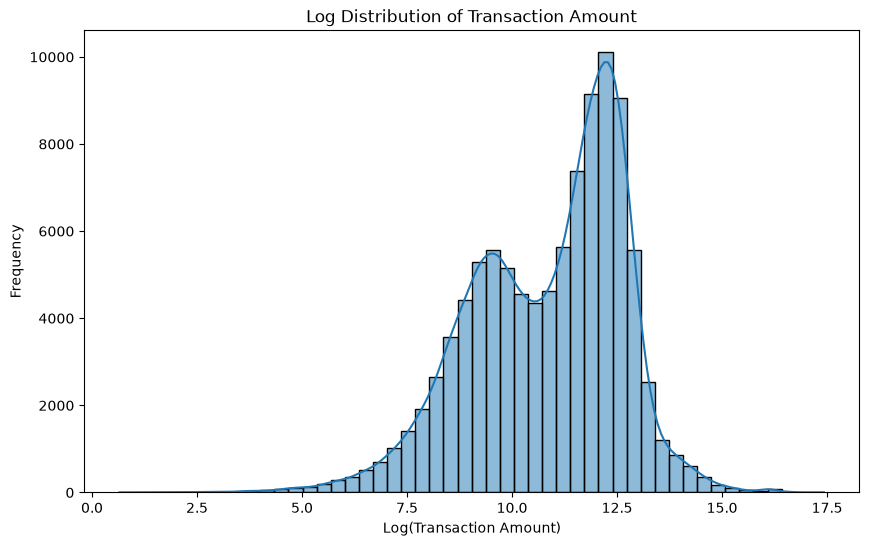

In [95]:
import numpy as np

plt.figure(figsize=(10, 6))
sns.histplot(
    np.log1p(sample_df['amount']),
    bins=50,
    kde=True
)
plt.title('Log Distribution of Transaction Amount')
plt.xlabel('Log(Transaction Amount)')
plt.ylabel('Frequency')

plt.show()

The log-transformed transaction amounts show a concentrated distribution, with most transactions occurring around the higher log-value range.

In [96]:
fraud_amount = df.groupby('isFraud')['amount'].describe()
print(fraud_amount)

             count          mean           std   min         25%        50%  \
isFraud                                                                       
0        6354407.0  1.781970e+05  5.962370e+05  0.01   13368.395   74684.72   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.330  441423.44   

                75%          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  


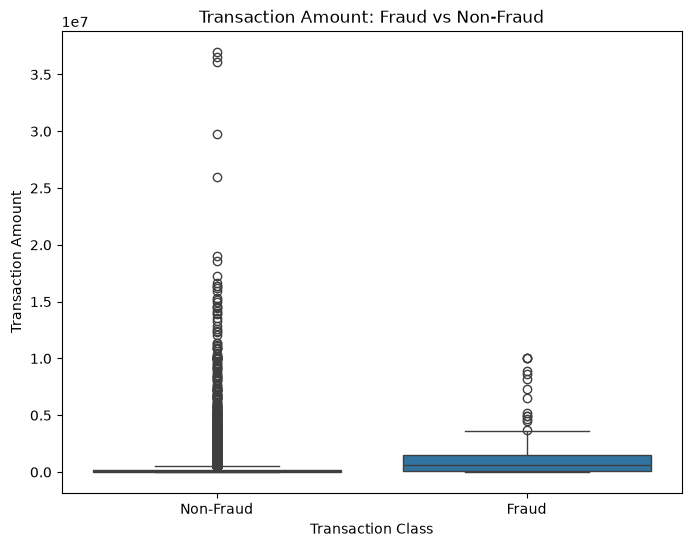

In [97]:
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=sample_df,
    x='isFraud',
    y='amount'
)
plt.title('Transaction Amount: Fraud vs Non-Fraud')
plt.xlabel('Transaction Class')
plt.ylabel('Transaction Amount')
plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

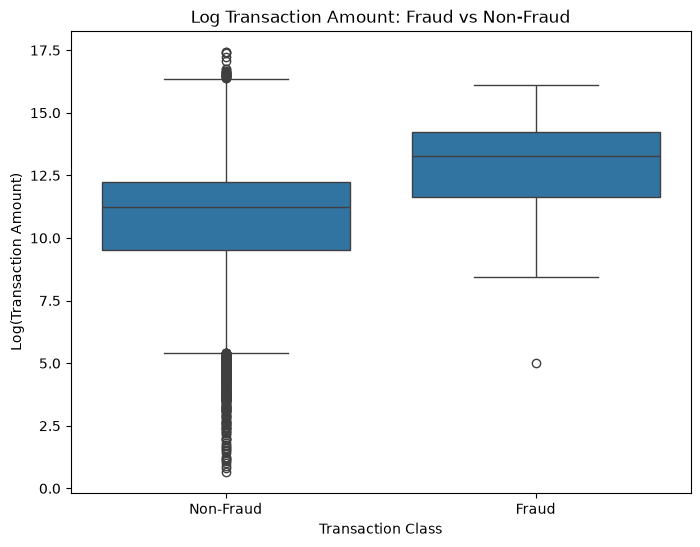

In [98]:
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=sample_df,
    x='isFraud',
    y=np.log1p(sample_df['amount'])
)
plt.title('Log Transaction Amount: Fraud vs Non-Fraud')
plt.xlabel('Transaction Class')
plt.ylabel('Log(Transaction Amount)')
plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

In PaySim Dataset, step represents time units.

In [99]:
#fraud rate per step:

fraud_by_step = df.groupby('step')['isFraud'].mean() * 100
print(fraud_by_step.head())

step
1    0.590842
2    0.788955
3    0.724638
4    1.769912
5    0.902256
Name: isFraud, dtype: float64


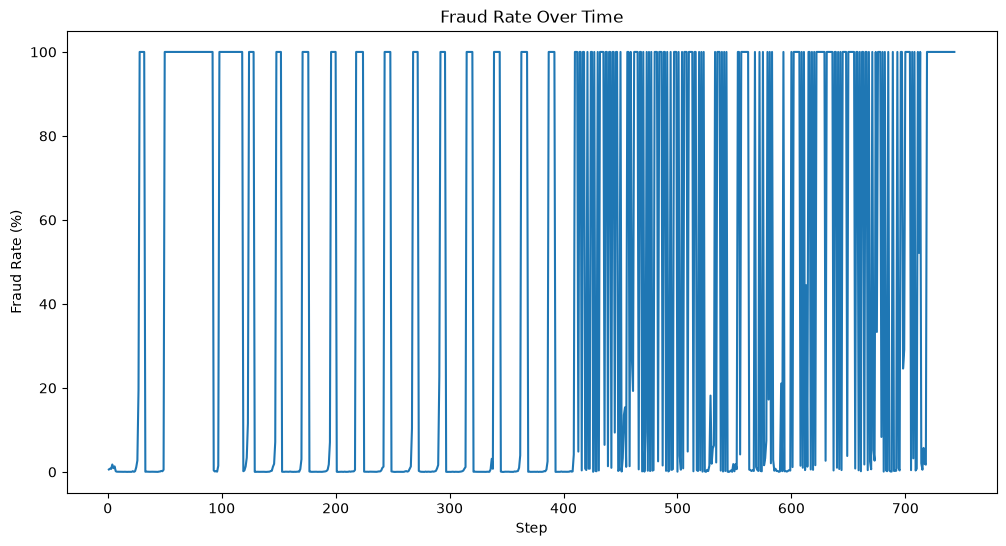

In [100]:
plt.figure(figsize=(12, 6))
plt.plot(fraud_by_step)
plt.title('Fraud Rate Over Time')
plt.xlabel('Step')
plt.ylabel('Fraud Rate (%)')

plt.show()

In [101]:
avg_amount = df.groupby('isFraud')['amount'].mean()
print(avg_amount)

isFraud
0    1.781970e+05
1    1.467967e+06
Name: amount, dtype: float64


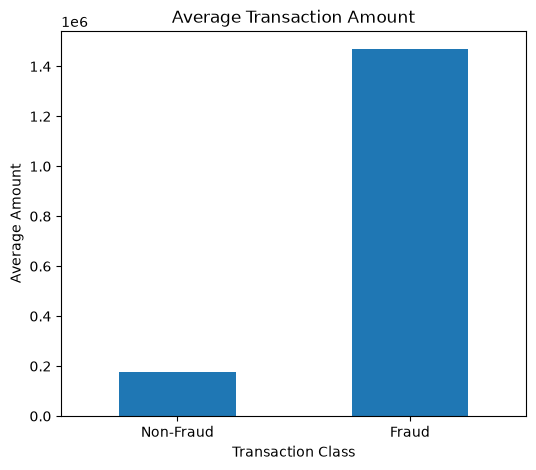

In [102]:
plt.figure(figsize=(6, 5))
avg_amount.plot(kind='bar')
plt.title('Average Transaction Amount')
plt.xlabel('Transaction Class')
plt.ylabel('Average Amount')
plt.xticks([0, 1], ['Non-Fraud', 'Fraud'], rotation=0)

plt.show()

In [103]:
flagged_vs_fraud = pd.crosstab(
    df['isFlaggedFraud'],
    df['isFraud']
)
print(flagged_vs_fraud)

isFraud               0     1
isFlaggedFraud               
0               6354407  8197
1                     0    16


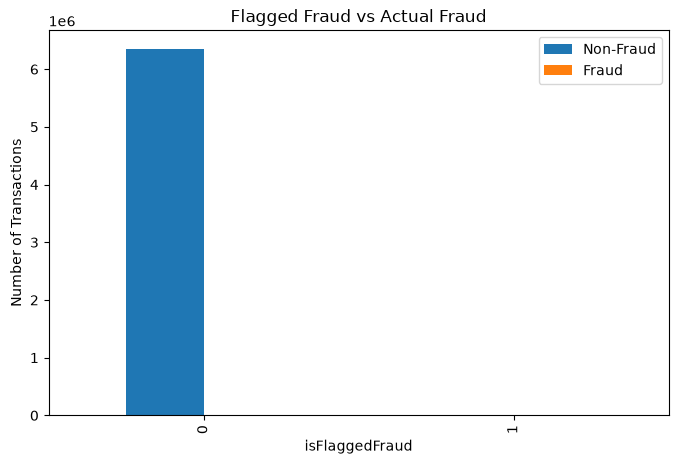

In [104]:
flagged_vs_fraud.plot(
    kind='bar',
    figsize=(8, 5)
)
plt.title('Flagged Fraud vs Actual Fraud')
plt.xlabel('isFlaggedFraud')
plt.ylabel('Number of Transactions')
plt.legend(['Non-Fraud', 'Fraud'])

plt.show()

In [105]:
balance_columns = [
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]
df.groupby('isFraud')[balance_columns].mean()

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,8.328287e+05,855970.228109,1.101421e+06,1.224926e+06
1,1.649668e+06,192392.631836,5.442496e+05,1.279708e+06


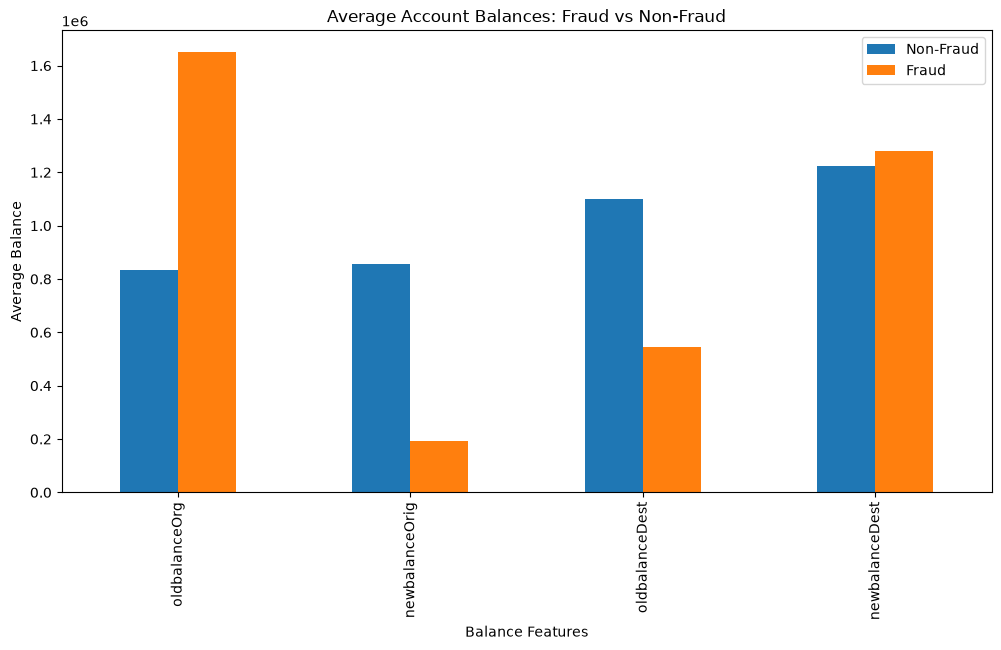

In [106]:
balance_means = df.groupby('isFraud')[balance_columns].mean()
balance_means.T.plot(
    kind='bar',
    figsize=(12, 6)
)
plt.title('Average Account Balances: Fraud vs Non-Fraud')
plt.xlabel('Balance Features')
plt.ylabel('Average Balance')
plt.legend(['Non-Fraud', 'Fraud'])

plt.show()

In [107]:
eda_summary = {
    'Total Transactions': len(df),
    'Fraudulent Transactions': df['isFraud'].sum(),
    'Non-Fraudulent Transactions': (df['isFraud'] == 0).sum(),
    'Fraud Percentage': df['isFraud'].mean() * 100,
    'Non-Fraud Percentage': (df['isFraud'] == 0).mean() * 100
}
for key, value in eda_summary.items():
    print(f'{key}: {value}')

Total Transactions: 6362620
Fraudulent Transactions: 8213
Non-Fraudulent Transactions: 6354407
Fraud Percentage: 0.12908204481801522
Non-Fraud Percentage: 99.87091795518198


Data Preprocessing & Feature Engineering

In [108]:
df.dtypes

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Dataset has both numerical and categorical features

In [109]:
# Onehot encode transaction type
df_encoded = pd.get_dummies(df, columns=['type'], drop_first=True)
df_encoded.head()

,step,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,False,False,True,False
1,1,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,False,False,True,False
2,1,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,False,False,False,True
3,1,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,True,False,False,False
4,1,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,False,False,True,False


In [110]:
X = df_encoded.drop('isFraud', axis=1)
y = df_encoded['isFraud']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6362620, 13)
Target shape: (6362620,)


In [111]:
#Checking class imbalance

y.value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [112]:
y.value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

The target variable is highly imbalanced, with fraudulent transactions representing only a very small percentage of the dataset.

In [113]:
# Difference between old and new origin balance
df_encoded['originBalanceDiff'] = (
    df_encoded['oldbalanceOrg'] - df_encoded['newbalanceOrig']
)

# Difference between old and new destination balance
df_encoded['destBalanceDiff'] = (
    df_encoded['newbalanceDest'] - df_encoded['oldbalanceDest']
)

df_encoded[['originBalanceDiff', 'destBalanceDiff']].head()

,originBalanceDiff,destBalanceDiff
0,9839.64,0.0
1,1864.28,0.0
2,181.00,0.0
3,181.00,-21182.0
4,11668.14,0.0


These features capture the change in account balances before and after a transaction.

In [114]:
#Transaction Amount to Origin Balance Ratio
df_encoded['amountToOriginRatio'] = (
    df_encoded['amount'] / (df_encoded['oldbalanceOrg'] + 1)
)
df_encoded[['amount', 'oldbalanceOrg', 'amountToOriginRatio']].head()

,amount,oldbalanceOrg,amountToOriginRatio
0,9839.64,170136.0,0.057834
1,1864.28,21249.0,0.087731
2,181.00,181.0,0.994505
3,181.00,181.0,0.994505
4,11668.14,41554.0,0.280788


This feature measures how large a transaction amount is relative to the sender's available balance.

In [115]:
#Transaction Amount to Destination Balance Ratio
df_encoded['amountToDestRatio'] = (
    df_encoded['amount'] / (df_encoded['oldbalanceDest'] + 1)
)
df_encoded[['amount', 'oldbalanceDest', 'amountToDestRatio']].head()

,amount,oldbalanceDest,amountToDestRatio
0,9839.64,0.0,9839.640000
1,1864.28,0.0,1864.280000
2,181.00,0.0,181.000000
3,181.00,21182.0,0.008545
4,11668.14,0.0,11668.140000


This feature measures the transaction amount relative to the destination account's existing balance.

In [116]:
#Balance Error Features

# Error between expected and actual origin balance
df_encoded['originBalanceError'] = (
    df_encoded['oldbalanceOrg']
    - df_encoded['amount']
    - df_encoded['newbalanceOrig']
)
# Error between expected and actual destination balance
df_encoded['destBalanceError'] = (
    df_encoded['oldbalanceDest']
    + df_encoded['amount']
    - df_encoded['newbalanceDest']
)
df_encoded[['originBalanceError', 'destBalanceError']].head()

,originBalanceError,destBalanceError
0,0.0,9839.64
1,0.0,1864.28
2,0.0,181.00
3,0.0,21363.00
4,0.0,11668.14


These features capture inconsistencies between expected and actual account balance changes, which may indicate suspicious transactions.

In [117]:
print("Updated dataset shape:", df_encoded.shape)
df_encoded.head()

Updated dataset shape: (6362620, 20)


,step,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,originBalanceDiff,destBalanceDiff,amountToOriginRatio,amountToDestRatio,originBalanceError,destBalanceError
0,1,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,False,False,True,False,9839.64,0.0,0.057834,9839.640000,0.0,9839.64
1,1,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,False,False,True,False,1864.28,0.0,0.087731,1864.280000,0.0,1864.28
2,1,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,False,False,False,True,181.00,0.0,0.994505,181.000000,0.0,181.00
3,1,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,True,False,False,False,181.00,-21182.0,0.994505,0.008545,0.0,21363.00
4,1,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,False,False,True,False,11668.14,0.0,0.280788,11668.140000,0.0,11668.14


In [118]:
#Redefining Features and Target

X = df_encoded.drop('isFraud', axis=1)
y = df_encoded['isFraud']
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6362620, 19)
Target shape: (6362620,)


In [119]:
#Train-Test Split

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (5090096, 19)
Testing set shape: (1272524, 19)


In [120]:
#Scaling Numerical Features

numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns
print(numerical_features)

Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFlaggedFraud', 'originBalanceDiff',
       'destBalanceDiff', 'amountToOriginRatio', 'amountToDestRatio',
       'originBalanceError', 'destBalanceError'],
      dtype='object')


In [121]:
#StandardScaler

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)
X_test[numerical_features] = scaler.transform(
    X_test[numerical_features]
)
print("Numerical features scaled successfully.")

Numerical features scaled successfully.


Model Building & Training

In [122]:
X_train = X_train.drop(['nameOrig', 'nameDest'], axis=1)
X_test = X_test.drop(['nameOrig', 'nameDest'], axis=1)

#nameOrig and nameDest are account identifiers, so they should not be directly used as raw features.

In [123]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (5090096, 17)
X_test shape: (1272524, 17)


In [124]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [125]:
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

In [134]:
#Classification Report
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98   1270881
           1       0.03      0.98      0.06      1643

    accuracy                           0.96   1272524
   macro avg       0.52      0.97      0.52   1272524
weighted avg       1.00      0.96      0.98   1272524



The classification report shows that the model achieves 98% recall for fraud cases, but the very low precision of 3% indicates that many non-fraud transactions are incorrectly predicted as fraud.

The classification report shows that the model achieves 98% recall for fraud cases, but the very low precision of 3% indicates that many non-fraud transactions are incorrectly predicted as fraud.

In [127]:
#confusion matrix
from sklearn.metrics import confusion_matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
print(cm_lr)

[[1224453   46428]
 [     31    1612]]


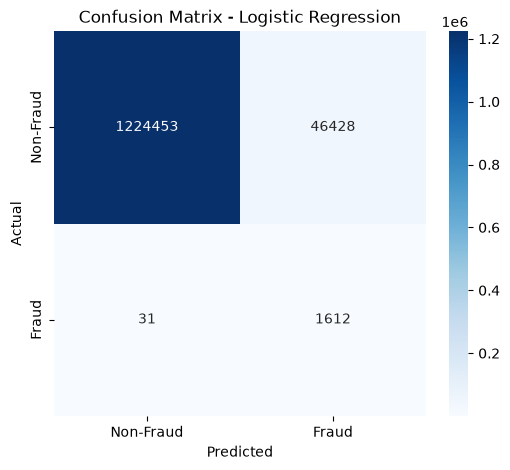

In [128]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Fraud', 'Fraud'],
    yticklabels=['Non-Fraud', 'Fraud']
)
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

The model correctly identifies 1,612 fraudulent transactions and misses only 31 fraud cases, but it also produces 46,428 false positives, incorrectly classifying many non-fraud transactions as fraud.

In [130]:
#ROC-AUC Score

from sklearn.metrics import roc_auc_score
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
print("ROC-AUC Score:", roc_auc_lr)

ROC-AUC Score: 0.9961966583464984


The ROC-AUC score of approximately 0.996 indicates that the Logistic Regression model has an excellent ability to distinguish between fraudulent and non-fraudulent transactions.

Model Improvement and Comparison

In [136]:
#Random Forest Model

from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [137]:
# Predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Classification Report
from sklearn.metrics import classification_report
print("Classification Report - Random Forest\n")
print(classification_report(y_test, y_pred_rf))

Classification Report - Random Forest

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       1.00      1.00      1.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      1.00      1.00   1272524
weighted avg       1.00      1.00      1.00   1272524



[[1270880       1]
 [      4    1639]]


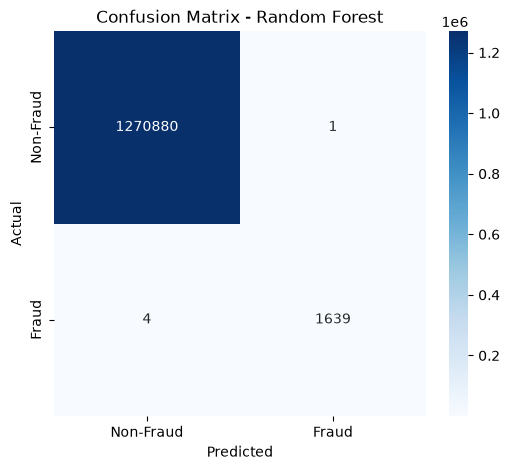

In [138]:
#Random Forest Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Fraud', 'Fraud'],
    yticklabels=['Non-Fraud', 'Fraud']
)
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

The Random Forest model correctly classifies almost all transactions, with only 1 false positive and 4 false negatives.

Random Forest ROC-AUC Score: 0.9990276876874659


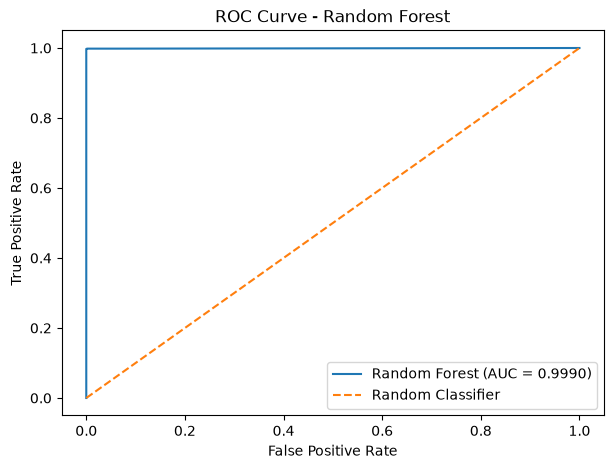

In [139]:
#ROC-AUC Score and ROC Curve

from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC Score:", roc_auc_rf)

fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)
plt.figure(figsize=(7, 5))
plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {roc_auc_rf:.4f})'
)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.show()

In [140]:
from sklearn.metrics import accuracy_score
import pandas as pd

accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_lr, accuracy_rf],
    'ROC-AUC Score': [roc_auc_lr, roc_auc_rf]
})
comparison

,Model,Accuracy,ROC-AUC Score
0,Logistic Regression,0.963491,0.996197
1,Random Forest,0.999996,0.999028


The Random Forest model outperforms Logistic Regression, achieving higher accuracy (99.996%) and ROC-AUC score (99.028%).

In [141]:
#Feature Importance Analysis for Random Forest to identify which features contribute most to fraud detection

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)
print(feature_importance)

                Feature  Importance
15   originBalanceError    0.274512
11    originBalanceDiff    0.193094
3        newbalanceOrig    0.135052
2         oldbalanceOrg    0.108554
9          type_PAYMENT    0.054549
1                amount    0.051656
14    amountToDestRatio    0.047774
13  amountToOriginRatio    0.027414
12      destBalanceDiff    0.026008
10        type_TRANSFER    0.018700
7         type_CASH_OUT    0.015960
16     destBalanceError    0.014359
0                  step    0.012617
5        newbalanceDest    0.010097
4        oldbalanceDest    0.007657
6        isFlaggedFraud    0.001262
8            type_DEBIT    0.000734


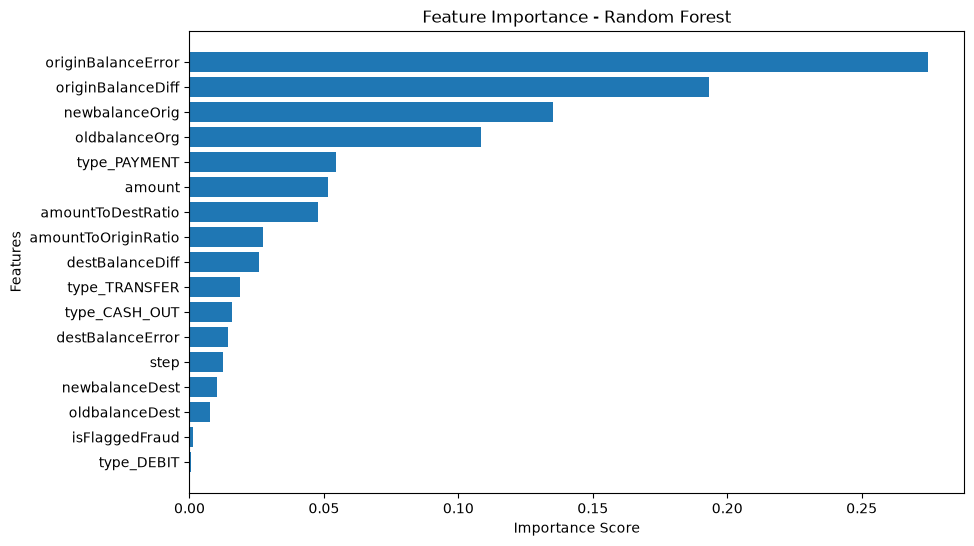

In [142]:
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.show()

In [143]:
#Saving Random Forest model

import joblib
joblib.dump(rf_model, 'random_forest_fraud_model.pkl')
print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [144]:
loaded_model = joblib.load('random_forest_fraud_model.pkl')
print("Model loaded successfully!")

Model loaded successfully!
